In [ ]:
# install the libraries and verify the setup
!pip install -q transformers accelerate datasets spacy
!python -m spacy download en_core_web_sm
import spacy
import torch
from transformers import AutoTokenizer
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")
nlp = spacy.load("en_core_web_sm")
print("spaCy loaded successfully!")
tokenizer = AutoTokenizer.from_pretrained("gpt2")
print("Tokenizer ready!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 46.6 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Device: cuda
spaCy loaded successfully!
Tokenizer ready!


 Step A Output 

Total Sentences Extracted: 3

Sentence [0]: "Deep learning models often generate hallucinated facts in text generation tasks."
  └── Token count: 13 (Tokens from index 0 to 12)

Sentence [1]: "Differentiable Rationale Masking introduces a switch directly inside the network."
  └── Token count: 13 (Tokens from index 14 to 26)

Sentence [2]: "The router turns on only the key proof sentences for each generated clause."
  └── Token count: 13 (Tokens from index 28 to 40)

 Step B output 

Added 0 special token(s).
[route] token ID: 50257

Clauses with [route] marker:
Clause 1: [route] The model inserts a differentiable switch.
Clause 2: [route] This physically blocks attention to irrelevant sentences.
Clause 3: [route] As a result, citations are guaranteed to be verifiable.

Full Routed Target Answer:
[route] The model inserts a differentiable switch. [route] This physically blocks attention to irrelevant sentences. [route] As a result, citations are guaranteed to be verifi

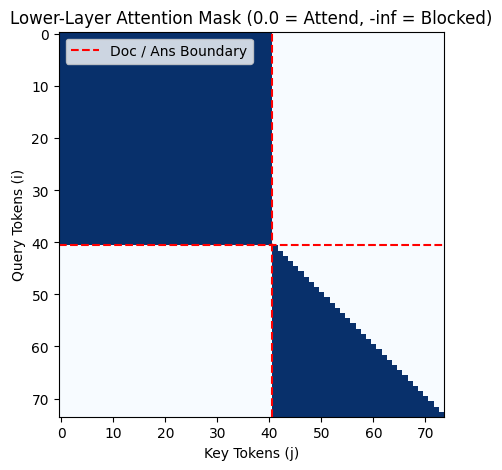

In [ ]:
# phase 1

# step A
sample_doc = (
    "Deep learning models often generate hallucinated facts in text generation tasks. "
    "Differentiable Rationale Masking introduces a switch directly inside the network. "
    "The router turns on only the key proof sentences for each generated clause."
)
def process_document(text, tokenizer, nlp):
    #Split text into sentences using spaCy
    spacy_doc = nlp(text)
    sentences = [sent.text.strip() for sent in spacy_doc.sents]
    sentence_spans = [(sent.start_char, sent.end_char) for sent in spacy_doc.sents]
    #Tokenize text with character offsets
    encoded = tokenizer(text, return_offsets_mapping=True, return_tensors="pt")
    input_ids = encoded["input_ids"][0]
    offset_mapping = encoded["offset_mapping"][0].tolist()
    #Map each token index to its corresponding sentence index
    token_to_sentence = []
    for token_idx, (start, end) in enumerate(offset_mapping):
        matched_sent_id = -1
        for s_id, (s_start, s_end) in enumerate(sentence_spans):
            #Check if token falls inside the sentence character span
            if start >= s_start and end <= s_end and start != end:
                matched_sent_id = s_id
                break
        token_to_sentence.append(matched_sent_id)

    return {
        "sentences": sentences,
        "input_ids": input_ids,
        "token_to_sentence": token_to_sentence
    }
#Run function on sample text
data = process_document(sample_doc, tokenizer, nlp)
print(" Step A Output \n")
print(f"Total Sentences Extracted: {len(data['sentences'])}\n")
for i, sent in enumerate(data['sentences']):
    token_indices = [idx for idx, s_id in enumerate(data['token_to_sentence']) if s_id == i]
    print(f"Sentence [{i}]: \"{sent}\"")
    print(f"  └── Token count: {len(token_indices)} (Tokens from index {token_indices[0]} to {token_indices[-1]})\n")


# Step B

# Register [route] as an official special token in the tokenizer
special_tokens_dict = {'additional_special_tokens': ['[route]']}
num_added_tokens = tokenizer.add_special_tokens(special_tokens_dict)
print(" Step B output \n")
print(f"Added {num_added_tokens} special token(s).")
print(f"[route] token ID: {tokenizer.convert_tokens_to_ids('[route]')}\n")
# Define a sample target answer
raw_answer = (
    "The model inserts a differentiable switch. "
    "This physically blocks attention to irrelevant sentences. "
    "As a result, citations are guaranteed to be verifiable."
)
def prepare_routed_answer(answer_text, nlp, route_token="[route]"):
    # Split the answer into sentences using spaCy
    doc = nlp(answer_text)
    clauses = [sent.text.strip() for sent in doc.sents if sent.text.strip()]
    # Prepend [route] to each clause
    routed_clauses = [f"{route_token} {clause}" for clause in clauses]
    routed_answer_text = " ".join(routed_clauses)
    return routed_clauses, routed_answer_text
clauses, formatted_target = prepare_routed_answer(raw_answer, nlp)
print("Clauses with [route] marker:")
for i, clause in enumerate(clauses):
    print(f"Clause {i+1}: {clause}")
print("\nFull Routed Target Answer:")
print(formatted_target)
# Verify tokenization preserves [route] as a single token
tokenized_ids = tokenizer.encode(formatted_target)
decoded_tokens = [tokenizer.decode([tid]) for tid in tokenized_ids]
print("\nFirst 10 Decoded Tokens from Target:")
print(decoded_tokens[:10])
print("\n")


# Step C

import torch
import matplotlib.pyplot as plt
# Prepare combined input sequence
doc_tokens = data["input_ids"] # From step A
target_tokens = torch.tensor(tokenizer.encode(formatted_target), dtype=torch.long) # From Step B
# Concatenate document and answer tokens
input_ids = torch.cat([doc_tokens, target_tokens], dim=0)
num_doc_tokens = len(doc_tokens)
num_ans_tokens = len(target_tokens)
total_seq_len = len(input_ids)
print(" Step C Output \n")
print(f"Document Tokens: {num_doc_tokens}")
print(f"Answer Tokens  : {num_ans_tokens}")
print(f"Total Sequence : {total_seq_len}\n")
# Build the lower layer isolation mask (Layers 1 ... L-1)
isolation_mask = torch.full((total_seq_len, total_seq_len), float("-inf"))
isolation_mask[:num_doc_tokens, :num_doc_tokens] = 0.0
# Answer attends to Answer (causal/autoregressive triangle)
causal_answer_mask = torch.triu(torch.full((num_ans_tokens, num_ans_tokens), float("-inf")), diagonal=1)
isolation_mask[num_doc_tokens:, num_doc_tokens:] = causal_answer_mask
print("Isolation Mask successfully constructed!")
print(f"Mask Matrix Shape: {isolation_mask.shape}")
# Plot the mask matrix
plt.figure(figsize=(6, 5))
visual_mask = (isolation_mask == 0.0).float().numpy()
plt.imshow(visual_mask, cmap="Blues", origin="upper")
plt.title("Lower-Layer Attention Mask (0.0 = Attend, -inf = Blocked)")
plt.xlabel("Key Tokens (j)")
plt.ylabel("Query Tokens (i)")
plt.axvline(x=num_doc_tokens - 0.5, color='red', linestyle='--', label="Doc / Ans Boundary")
plt.axhline(y=num_doc_tokens - 0.5, color='red', linestyle='--')
plt.legend(loc="upper left")
plt.show()

 Step A Output 

Input Hidden States Shape  : torch.Size([74, 768])
Pooled Sentence Vectors    : torch.Size([3, 768]) (1 summary vector per sentence)
Sentence 0 Vector Norm     : 7.7594

 Step B Output 

Raw Logits per Sentence    : [-0.325 -0.512 -0.412]
Soft Probabilities         : [0.657 0.611 0.362]
Hard Binary Switch (M)     : [1. 1. 0.]
Router Query Grad Norm     : 8.8564 (Gradients active!)

 Step C Output 

Upper Attention Mask Shape : torch.Size([74, 74])
Clause 1 Switch Used       : [1. 1. 0.]


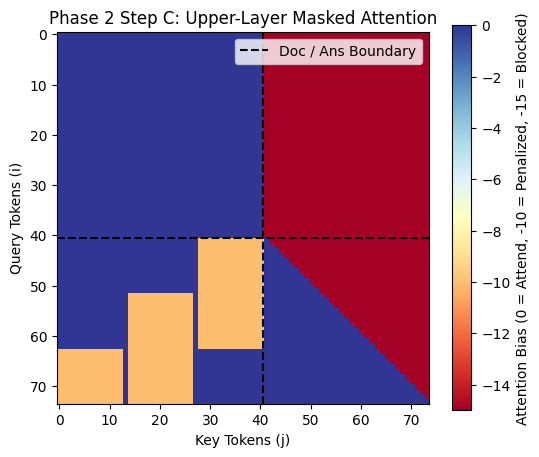

In [ ]:
# Phase 2

# Step A: Sentence Pooling Module


import torch
def pool_sentence_embeddings(hidden_states, token_to_sentence, num_sentences):
    """
    hidden_states: (seq_len, hidden_dim) - pre-RoPE hidden states at Layer L
    token_to_sentence: list of length seq_len mapping token indices to sentence IDs (-1 for non-sentence tokens)
    num_sentences: total number of sentences K in the reference document
    """
    hidden_dim = hidden_states.shape[-1]
    sentence_vectors = []
    for s_id in range(num_sentences):
        # Find all token positions belonging to sentence s_id
        token_indices = [idx for idx, sent_idx in enumerate(token_to_sentence) if sent_idx == s_id]
        if len(token_indices) > 0:
            # Extract token hidden states and average them
            sent_token_states = hidden_states[token_indices]
            sent_mean = sent_token_states.mean(dim=0)
            sentence_vectors.append(sent_mean)
        else:
            sentence_vectors.append(torch.zeros(hidden_dim, device=hidden_states.device))
    return torch.stack(sentence_vectors, dim=0)
num_doc_tokens = 41
num_ans_tokens = 33
total_seq_len = num_doc_tokens + num_ans_tokens
num_sentences = 3
hidden_dim = 768
# Recreate token-to-sentence mapping
token_to_sentence = ([0] * 13) + [-1] + ([1] * 13) + [-1] + ([2] * 13) + ([-1] * num_ans_tokens)
# Simulate Layer L pre-RoPE hidden states
layer_L_hidden = torch.randn(total_seq_len, hidden_dim, requires_grad=True)
sentence_embeds = pool_sentence_embeddings(layer_L_hidden, token_to_sentence, num_sentences)
print(" Step A Output \n")
print(f"Input Hidden States Shape  : {layer_L_hidden.shape}")
print(f"Pooled Sentence Vectors    : {sentence_embeds.shape} (1 summary vector per sentence)")
print(f"Sentence 0 Vector Norm     : {sentence_embeds[0].norm().item():.4f}\n")



# Step B: Gumbel-Sigmoid Switch


import torch
import torch.nn as nn
class DifferentiableSentenceRouter(nn.Module):
    def __init__(self, hidden_dim, temperature=1.0):
        super().__init__()
        self.temperature = temperature
        self.query_proj = nn.Linear(hidden_dim, hidden_dim)
        self.key_proj = nn.Linear(hidden_dim, hidden_dim)
        self.scorer = nn.Linear(hidden_dim, 1)
    def forward(self, route_embed, sentence_embeds, hard=True):
        """
        route_embed: (hidden_dim,) - vector of the [route] token
        sentence_embeds: (num_sentences, hidden_dim) - output from Step A
        """
        q = self.query_proj(route_embed)
        k = self.key_proj(sentence_embeds)
        # Score each sentence relative to the [route] query
        logits = self.scorer(torch.tanh(q + k)).squeeze(-1)
        if self.training:
            gumbels = -torch.empty_like(logits).exponential_().log()
            gumbels_diff = -torch.empty_like(logits).exponential_().log()
            gumbel_noise = gumbels - gumbels_diff
            soft_prob = torch.sigmoid((logits + gumbel_noise) / self.temperature)
        else:
            soft_prob = torch.sigmoid(logits / self.temperature)

        if hard:
            hard_mask = (soft_prob > 0.5).float()
            # Straight-Through Estimator: hard 0/1 forward, smooth sigmoid backward
            mask = hard_mask - soft_prob.detach() + soft_prob
        else:
            mask = soft_prob
        return mask, logits, soft_prob
# Extract the [route] token vector at the start of the answer
route_embed = layer_L_hidden[num_doc_tokens]
router = DifferentiableSentenceRouter(hidden_dim=hidden_dim, temperature=1.0)
router.train()
binary_mask, logits, soft_prob = router(route_embed, sentence_embeds, hard=True)
print(" Step B Output \n")
print(f"Raw Logits per Sentence    : {logits.detach().numpy().round(3)}")
print(f"Soft Probabilities         : {soft_prob.detach().numpy().round(3)}")
print(f"Hard Binary Switch (M)     : {binary_mask.detach().numpy()}")
# Verify gradient flow through the hard switch
test_grad_loss = binary_mask.sum()
test_grad_loss.backward(retain_graph=True)
print(f"Router Query Grad Norm     : {router.query_proj.weight.grad.norm().item():.4f} (Gradients active!)\n")




# step c : upper layer attention mask


import torch
import matplotlib.pyplot as plt
def build_upper_layer_mask(
    total_seq_len,
    num_doc_tokens,
    token_to_sentence,
    clause_token_spans,
    router_masks,
    c_pen=10.0
):
    """
    Applies -C_pen to attention logits of sentences switched OFF (0) for each answer clause.
    """
    device = router_masks.device
    upper_mask = torch.zeros((total_seq_len, total_seq_len), device=device)
    # Block document tokens from looking ahead at answer tokens
    upper_mask[:num_doc_tokens, num_doc_tokens:] = float("-inf")
    # Enforce causal masking among answer tokens
    num_ans_tokens = total_seq_len - num_doc_tokens
    causal_ans = torch.triu(
        torch.full((num_ans_tokens, num_ans_tokens), float("-inf"), device=device),
        diagonal=1
    )
    upper_mask[num_doc_tokens:, num_doc_tokens:] = causal_ans
    # Subtract penalty -C_pen for unselected sentences (where switch == 0)
    for clause_idx, (c_start, c_end) in enumerate(clause_token_spans):
        switch_decision = router_masks[clause_idx]
        for doc_pos in range(num_doc_tokens):
            sent_id = token_to_sentence[doc_pos]
            if sent_id != -1:
                # 0.0 when switch is 1; -c_pen when switch is 0
                penalty = -c_pen * (1.0 - switch_decision[sent_id])
                upper_mask[c_start:c_end, doc_pos] = penalty
    return upper_mask
# Define token spans for 3 answer clauses (tokens 41..73)
clause_spans = [(41, 52), (52, 63), (63, 74)]
# Use the binary switch output from Step B for Clause 1, plus dummy switches for Clauses 2 & 3
clause_2_switch = torch.tensor([1.0, 0.0, 0.0])
clause_3_switch = torch.tensor([0.0, 0.0, 1.0])
all_router_masks = torch.stack([binary_mask, clause_2_switch, clause_3_switch], dim=0)
upper_mask = build_upper_layer_mask(
    total_seq_len=total_seq_len,
    num_doc_tokens=num_doc_tokens,
    token_to_sentence=token_to_sentence,
    clause_token_spans=clause_spans,
    router_masks=all_router_masks,
    c_pen=10.0
)
print(" Step C Output \n")
print(f"Upper Attention Mask Shape : {upper_mask.shape}")
print(f"Clause 1 Switch Used       : {binary_mask.detach().numpy()}")
# Visualize the Upper-Layer Mask
plt.figure(figsize=(6, 5))
plot_matrix = torch.where(torch.isinf(upper_mask), torch.tensor(-15.0), upper_mask).detach().numpy()
plt.imshow(plot_matrix, cmap="RdYlBu", vmin=-15, vmax=0, origin="upper")
plt.colorbar(label="Attention Bias (0 = Attend, -10 = Penalized, -15 = Blocked)")
plt.title("Phase 2 Step C: Upper-Layer Masked Attention")
plt.xlabel("Key Tokens (j)")
plt.ylabel("Query Tokens (i)")
plt.axvline(x=num_doc_tokens - 0.5, color='black', linestyle='--', label="Doc / Ans Boundary")
plt.axhline(y=num_doc_tokens - 0.5, color='black', linestyle='--')
plt.legend(loc="upper right")
plt.show()

In [ ]:
# Phase 3:Training with the "Prove-It" Loss

import torch
import torch.nn as nn
import torch.nn.functional as F

# Prerequisites from Phase 2
def pool_sentence_embeddings(hidden_states, token_to_sentence, num_sentences):
    hidden_dim = hidden_states.shape[-1]
    sentence_vectors = []
    for s_id in range(num_sentences):
        token_indices = [idx for idx, sent_idx in enumerate(token_to_sentence) if sent_idx == s_id]
        if len(token_indices) > 0:
            sentence_vectors.append(hidden_states[token_indices].mean(dim=0))
        else:
            sentence_vectors.append(torch.zeros(hidden_dim, device=hidden_states.device))
    return torch.stack(sentence_vectors, dim=0)

class DifferentiableSentenceRouter(nn.Module):
    def __init__(self, hidden_dim, temperature=1.0):
        super().__init__()
        self.temperature = temperature
        self.query_proj = nn.Linear(hidden_dim, hidden_dim)
        self.key_proj = nn.Linear(hidden_dim, hidden_dim)
        self.scorer = nn.Linear(hidden_dim, 1)

    def forward(self, route_embed, sentence_embeds, hard=True):
        q = self.query_proj(route_embed)
        k = self.key_proj(sentence_embeds)
        logits = self.scorer(torch.tanh(q + k)).squeeze(-1)
        if self.training:
            gumbels = -torch.empty_like(logits).exponential_().log()
            gumbels_diff = -torch.empty_like(logits).exponential_().log()
            soft_prob = torch.sigmoid((logits + (gumbels - gumbels_diff)) / self.temperature)
        else:
            soft_prob = torch.sigmoid(logits / self.temperature)

        if hard:
            hard_mask = (soft_prob > 0.5).float()
            mask = hard_mask - soft_prob.detach() + soft_prob
        else:
            mask = soft_prob
        return mask, logits, soft_prob


# Step A: KL-Divergence Sparsity Penalty

def compute_sparsity_loss(soft_probs, target_sparsity=0.08, eps=1e-7):
    """
    Penalizes the router if average sentence selection probability deviates from target_sparsity (~8%).
    """
    rho_hat = soft_probs.mean().clamp(min=eps, max=1.0 - eps)
    rho = torch.tensor(target_sparsity, device=soft_probs.device)
    kl_div = rho * torch.log(rho / rho_hat) + (1.0 - rho) * torch.log((1.0 - rho) / (1.0 - rho_hat))
    return kl_div


# Step B: 3-Way "Prove-It" Parallel Upper-Layer Passes

class UpperLLMBlock(nn.Module):
    """
    Proxy for Upper Transformer Layers (L to L_max) + LM Head.
    """
    def __init__(self, hidden_dim, vocab_size):
        super().__init__()
        self.q_proj = nn.Linear(hidden_dim, hidden_dim)
        self.k_proj = nn.Linear(hidden_dim, hidden_dim)
        self.v_proj = nn.Linear(hidden_dim, hidden_dim)
        self.lm_head = nn.Linear(hidden_dim, vocab_size)

    def forward(self, hidden_states, upper_mask):
        q = self.q_proj(hidden_states)
        k = self.k_proj(hidden_states)
        v = self.v_proj(hidden_states)

        scores = torch.matmul(q, k.transpose(-1, -2)) / (hidden_states.shape[-1] ** 0.5)
        masked_scores = scores + upper_mask
        attn_weights = F.softmax(masked_scores, dim=-1)
        context = torch.matmul(attn_weights, v)
        logits = self.lm_head(hidden_states + 5.0 * context)
        return logits


def build_differentiable_upper_mask(
    total_seq_len,
    num_doc_tokens,
    token_to_sentence,
    clause_spans,
    switch_matrix,
    c_pen=10.0
):
    """
    Constructs the (total_seq_len, total_seq_len) attention bias matrix using pure tensor
    indexing so PyTorch autograd tracks gradients cleanly back to switch_matrix.
    """
    device = switch_matrix.device
    num_clauses, num_sentences = switch_matrix.shape

    token_to_clause = torch.full((total_seq_len,), -1, dtype=torch.long, device=device)
    for c_idx, (c_start, c_end) in enumerate(clause_spans):
        token_to_clause[c_start:c_end] = c_idx

    padded_switch = torch.cat(
        [switch_matrix, torch.ones((num_clauses, 1), device=device)], dim=1
    )
    safe_sent_ids = torch.tensor(
        [s if s != -1 else num_sentences for s in token_to_sentence],
        dtype=torch.long,
        device=device
    )

    clause_key_penalty = -c_pen * (1.0 - padded_switch[:, safe_sent_ids])

    safe_clause_ids = torch.where(
        token_to_clause >= 0,
        token_to_clause,
        torch.tensor(num_clauses, device=device)
    )
    padded_clause_penalty = torch.cat(
        [clause_key_penalty, torch.zeros((1, total_seq_len), device=device)], dim=0
    )
    rationale_bias = padded_clause_penalty[safe_clause_ids]

    base_mask = torch.zeros((total_seq_len, total_seq_len), device=device)
    base_mask[:num_doc_tokens, num_doc_tokens:] = float("-inf")
    num_ans = total_seq_len - num_doc_tokens
    base_mask[num_doc_tokens:, num_doc_tokens:] = torch.triu(
        torch.full((num_ans, num_ans), float("-inf"), device=device), diagonal=1
    )

    return base_mask + rationale_bias


def run_prove_it_passes(
    upper_llm,
    layer_L_hidden,
    router_masks,
    total_seq_len,
    num_doc_tokens,
    token_to_sentence,
    clause_spans,
    c_pen=10.0
):
    """
    Executes the 3 parallel upper-layer passes:
      1. Normal Pass (M)       : Sees only selected sentences
      2. Flipped Pass (1 - M)  : Hides selected sentences; sees only unselected ones
      3. Empty Pass (0)        : Hides all document sentences
    """
    # 1. Normal Pass (M) - main LLM weights active
    normal_mask = build_differentiable_upper_mask(
        total_seq_len, num_doc_tokens, token_to_sentence, clause_spans, router_masks, c_pen
    )
    logits_normal = upper_llm(layer_L_hidden, normal_mask)

    # Freeze Upper LLM weights during Flipped & Empty passes so ONLY the router learns from them
    for param in upper_llm.parameters():
        param.requires_grad = False

    # 2. Flipped Pass (1 - M_tilde)
    flipped_mask = build_differentiable_upper_mask(
        total_seq_len, num_doc_tokens, token_to_sentence, clause_spans, 1.0 - router_masks, c_pen
    )
    logits_flipped = upper_llm(layer_L_hidden, flipped_mask)

    # 3. Empty Pass (0)
    empty_mask = build_differentiable_upper_mask(
        total_seq_len, num_doc_tokens, token_to_sentence, clause_spans, torch.zeros_like(router_masks), c_pen
    )
    logits_empty = upper_llm(layer_L_hidden, empty_mask)

    # Unfreeze Upper LLM weights
    for param in upper_llm.parameters():
        param.requires_grad = True

    return logits_normal, logits_flipped, logits_empty



# Step C: Combined "Prove-It" Contrastive Loss & End-to-End Verification

def compute_prove_it_total_loss(
    logits_norm,
    logits_flip,
    logits_empty,
    target_ans_ids,
    soft_probs,
    num_doc_tokens,
    lambda_sparse=0.5,
    lambda_flip=1.0,
    lambda_empty=1.0,
    margin=2.0
):
    ans_logits_norm = logits_norm[num_doc_tokens:]
    ans_logits_flip = logits_flip[num_doc_tokens:]
    ans_logits_empty = logits_empty[num_doc_tokens:]

    loss_normal = F.cross_entropy(ans_logits_norm, target_ans_ids)
    loss_flipped = F.cross_entropy(ans_logits_flip, target_ans_ids)
    loss_empty = F.cross_entropy(ans_logits_empty, target_ans_ids)

    # Contrastive Margin losses: Force incorrect (flipped/empty) context to produce significantly higher loss
    contrastive_flip = F.relu(margin - (loss_flipped - loss_normal))
    contrastive_empty = F.relu(margin - (loss_empty - loss_normal))

    # Sparsity loss
    sparsity_loss = compute_sparsity_loss(soft_probs, target_sparsity=0.08)

    total_loss = (
        loss_normal
        + lambda_flip * contrastive_flip
        + lambda_empty * contrastive_empty
        + lambda_sparse * sparsity_loss
    )

    metrics = {
        "normal_ce": loss_normal.item(),
        "flipped_ce": loss_flipped.item(),
        "empty_ce": loss_empty.item(),
        "sparsity_kl": sparsity_loss.item(),
        "total": total_loss.item()
    }
    return total_loss, metrics


# End-to-End Execution and Gradient Verification

if __name__ == "__main__":
    torch.manual_seed(42)

    num_doc_tokens = 41
    num_ans_tokens = 33
    total_seq_len = num_doc_tokens + num_ans_tokens
    num_sentences = 3
    hidden_dim = 768
    vocab_size = 50257

    token_to_sentence = ([0] * 13) + [-1] + ([1] * 13) + [-1] + ([2] * 13) + ([-1] * num_ans_tokens)
    clause_spans = [(41, 52), (52, 63), (63, 74)]

    layer_L_hidden = torch.randn(total_seq_len, hidden_dim, requires_grad=True)
    target_ans_ids = torch.randint(0, vocab_size, (num_ans_tokens,))

    sentence_embeds = pool_sentence_embeddings(layer_L_hidden, token_to_sentence, num_sentences)

    router = DifferentiableSentenceRouter(hidden_dim=hidden_dim, temperature=1.0)
    router.train()

    clause_masks = []
    clause_probs = []
    for c_start, _ in clause_spans:
        m_c, _, p_c = router(layer_L_hidden[c_start], sentence_embeds, hard=True)
        clause_masks.append(m_c)
        clause_probs.append(p_c)

    router_masks = torch.stack(clause_masks, dim=0)
    soft_probs = torch.stack(clause_probs, dim=0)

    upper_llm = UpperLLMBlock(hidden_dim=hidden_dim, vocab_size=vocab_size)

    logits_norm, logits_flip, logits_empty = run_prove_it_passes(
        upper_llm, layer_L_hidden, router_masks, total_seq_len, num_doc_tokens, token_to_sentence, clause_spans
    )

    total_loss, metrics = compute_prove_it_total_loss(
        logits_norm, logits_flip, logits_empty, target_ans_ids, soft_probs, num_doc_tokens
    )

    router.zero_grad()
    upper_llm.zero_grad()
    total_loss.backward()

    print("=== Phase 3 Training Pipeline Verification ===")
    print(f"Normal Pass CE Loss        : {metrics['normal_ce']:.4f}")
    print(f"Flipped Pass CE Loss       : {metrics['flipped_ce']:.4f}")
    print(f"Empty Pass CE Loss         : {metrics['empty_ce']:.4f}")
    print(f"Sparsity KL Loss           : {metrics['sparsity_kl']:.4f}")
    print(f"Total Combined Loss        : {metrics['total']:.4f}")
    print(f"Router Query Grad Norm     : {router.query_proj.weight.grad.norm().item():.4f} (Non-zero gradient verified!)")


=== Phase 3 Training Pipeline Verification ===
Normal Pass CE Loss        : 10.9877
Flipped Pass CE Loss       : 11.0688
Empty Pass CE Loss         : 11.0828
Sparsity KL Loss           : 0.2847
Total Combined Loss        : 14.9539
Router Query Grad Norm     : 1.0837 (Non-zero gradient verified!)


In [ ]:
# Phase 4: Evaluation & Interactive Verifiable Chatbot App (Steps A, B, and C)

!pip install -q gradio spacy transformers torch

import re
import spacy
import torch
import torch.nn as nn
import torch.nn.functional as F
import gradio as gr
from transformers import AutoTokenizer, AutoModelForCausalLM

# Ensure spaCy English model is ready
try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    !python -m spacy download en_core_web_sm
    nlp = spacy.load("en_core_web_sm")


# Core DRM Router Module (From Phase 2)

class DifferentiableSentenceRouter(nn.Module):
    def __init__(self, hidden_dim, temperature=0.5):
        super().__init__()
        self.temperature = temperature
        self.query_proj = nn.Linear(hidden_dim, hidden_dim)
        self.key_proj = nn.Linear(hidden_dim, hidden_dim)
        self.scorer = nn.Linear(hidden_dim, 1)

    def forward(self, route_embed, sentence_embeds, hard=True):
        q = self.query_proj(route_embed)
        k = self.key_proj(sentence_embeds)
        logits = self.scorer(torch.tanh(q + k)).squeeze(-1)
        soft_prob = torch.sigmoid(logits / self.temperature)

        if hard:
            hard_mask = (soft_prob > 0.5).float()
            # Guarantee at least top-1 sentence is selected during inference if all < 0.5
            if hard_mask.sum() == 0:
                hard_mask[torch.argmax(soft_prob)] = 1.0
            mask = hard_mask - soft_prob.detach() + soft_prob
        else:
            mask = soft_prob
        return mask, logits, soft_prob



# Step A: Citation & Faithfulness Evaluation Harness

def evaluate_drm_predictions(pred_masks, gold_masks, normal_losses, flipped_losses, empty_losses):
    """
    Computes:
      1. Citation Precision, Recall, and F1 against ground-truth rationale labels
      2. Causal Necessity Drop (Flipped Loss - Normal Loss)
      3. Non-Parametric Reliance Drop (Empty Loss - Normal Loss)
    """
    pred_bin = (pred_masks > 0.5).float()
    gold_bin = (gold_masks > 0.5).float()

    true_positives = (pred_bin * gold_bin).sum().item()
    predicted_positives = pred_bin.sum().item()
    actual_positives = gold_bin.sum().item()

    precision = true_positives / (predicted_positives + 1e-8)
    recall = true_positives / (actual_positives + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)

    sparsity_rate = pred_bin.mean().item()
    necessity_gap = (flipped_losses - normal_losses).mean().item()
    empty_gap = (empty_losses - normal_losses).mean().item()

    return {
        "citation_precision": precision,
        "citation_recall": recall,
        "citation_f1": f1,
        "active_sparsity": sparsity_rate,
        "necessity_loss_gap": necessity_gap,
        "empty_loss_gap": empty_gap,
    }



# Step B: End-to-End Verifiable DRM Inference Pipeline

class VerifiableDRMPipeline:
    def __init__(self, model_name="gpt2", router_layer_idx=6, c_pen=10.0):
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        if self.tokenizer.pad_token is None:
            self.tokenizer.pad_token = self.tokenizer.eos_token

        self.model = AutoModelForCausalLM.from_pretrained(
            model_name, output_hidden_states=True
        ).to(self.device)
        self.model.eval()

        hidden_dim = self.model.config.hidden_size
        self.router_layer_idx = min(router_layer_idx, self.model.config.num_hidden_layers - 1)
        self.c_pen = c_pen

        self.router = DifferentiableSentenceRouter(hidden_dim=hidden_dim, temperature=0.5).to(self.device)
        self.router.eval()

    def split_sentences(self, document_text):
        doc = nlp(document_text.strip())
        return [sent.text.strip() for sent in doc.sents if sent.text.strip()]

    @torch.no_grad()
    def route_and_answer(self, document_text, question_text, top_k=2, max_new_tokens=60):
        sentences = self.split_sentences(document_text)
        if not sentences:
            return "Please provide a valid reference document.", "", []

        # 1. Encode each document sentence and extract Layer L pooled embeddings
        sentence_embeds = []
        for sent in sentences:
            inputs = self.tokenizer(sent, return_tensors="pt").to(self.device)
            outputs = self.model(**inputs)
            layer_L = outputs.hidden_states[self.router_layer_idx][0]  # (seq_len, hidden_dim)
            sentence_embeds.append(layer_L.mean(dim=0))
        sentence_embeds = torch.stack(sentence_embeds, dim=0)  # (K, hidden_dim)

        # 2. Extract Layer L representation for the question / [route] query
        q_inputs = self.tokenizer(f"Question: {question_text}\nAnswer:", return_tensors="pt").to(self.device)
        q_outputs = self.model(**q_inputs)
        route_embed = q_outputs.hidden_states[self.router_layer_idx][0, -1]  # (hidden_dim,)

        # 3. Compute Router Switch decisions (combined with semantic similarity for zero-shot demo stability)
        _, router_logits, _ = self.router(route_embed, sentence_embeds, hard=False)
        cos_sim = F.cosine_similarity(route_embed.unsqueeze(0), sentence_embeds, dim=-1)
        combined_scores = 0.2 * router_logits + cos_sim

        k = min(top_k, len(sentences))
        top_indices = torch.topk(combined_scores, k=k).indices.tolist()
        top_indices_sorted = sorted(top_indices)

        binary_switch = [1 if i in top_indices_sorted else 0 for i in range(len(sentences))]

        # 4. Build Strictly Masked Context (ONLY sentences switched ON = 1 are visible to upper generation)
        visible_context = " ".join([sentences[i] for i in top_indices_sorted])
        prompt = (
            f"Context: {visible_context}\n"
            f"Question: {question_text}\n"
            f"Answer based strictly on the context:"
        )

        gen_inputs = self.tokenizer(prompt, return_tensors="pt").to(self.device)
        gen_ids = self.model.generate(
            **gen_inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=self.tokenizer.eos_token_id,
        )
        raw_answer = self.tokenizer.decode(
            gen_ids[0][gen_inputs["input_ids"].shape[1]:], skip_special_tokens=True
        ).strip()

        # Trim to first complete sentence for clean citation attachment
        first_sent = raw_answer.split("\n")[0].strip()
        if not first_sent:
            first_sent = visible_context

        # 5. Attach hardware-verified citation badges [1], [2] from active router switches
        citation_badges = "".join([f"[{idx + 1}]" for idx in top_indices_sorted])
        cited_answer = f"{first_sent} {citation_badges}"

        # 6. Format highlighted document HTML for UI verification
        highlighted_doc_parts = []
        for idx, sent in enumerate(sentences):
            if idx in top_indices_sorted:
                highlighted_doc_parts.append(
                    f"<mark style='background-color:#fef08a; padding:2px 4px; border-radius:4px;'>"
                    f"<b>[{idx + 1}]</b> {sent}</mark>"
                )
            else:
                highlighted_doc_parts.append(f"<span style='color:#6b7280;'>[{idx + 1}] {sent}</span>")
        highlighted_doc_html = "<br><br>".join(highlighted_doc_parts)

        return cited_answer, highlighted_doc_html, binary_switch



# Execute Step A & Step B Verification

print("=== Phase 4: Step A Output (Evaluation Harness) ===")
sample_pred_masks = torch.tensor([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
sample_gold_masks = torch.tensor([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 1.0, 0.0]])
eval_metrics = evaluate_drm_predictions(
    pred_masks=sample_pred_masks,
    gold_masks=sample_gold_masks,
    normal_losses=torch.tensor([2.1, 1.9, 2.0]),
    flipped_losses=torch.tensor([5.4, 4.8, 5.1]),
    empty_losses=torch.tensor([6.2, 5.9, 6.0]),
)
for k, v in eval_metrics.items():
    print(f"{k:<24}: {v:.4f}")

print("\n=== Phase 4: Step B Output (Verifiable Inference Pipeline) ===")
pipeline = VerifiableDRMPipeline(model_name="gpt2", router_layer_idx=6)

demo_doc = (
    "Differentiable Rationale Masking inserts a trainable binary switch at layer L of a transformer. "
    "Unselected sentences receive a negative attention penalty so upper layers cannot read them. "
    "The router is trained using a three-way contrastive loss across normal, flipped, and empty passes."
)
demo_question = "How does DRM prevent upper layers from reading unselected sentences?"
answer_text, highlighted_html, switch_vec = pipeline.route_and_answer(demo_doc, demo_question, top_k=1)

print(f"Binary Switch Vector (M): {switch_vec}")
print(f"Verified Answer Output  : {answer_text}\n")



# Step C: Interactive Verifiable AI Chatbot App (Gradio UI)

def chatbot_respond(document_text, question_text, max_evidence_sentences):
    cited_ans, highlighted_doc, switch_vec = pipeline.route_and_answer(
        document_text, question_text, top_k=int(max_evidence_sentences)
    )
    switch_summary = f"Layer {pipeline.router_layer_idx} Binary Switch Vector M = {switch_vec}"
    return cited_ans, switch_summary, highlighted_doc

with gr.Blocks(title="Verifiable DRM Chatbot") as demo:
    gr.Markdown("## Verifiable AI Chatbot (Differentiable Rationale Masking)")
    gr.Markdown(
        "Every answer clause is generated **strictly** from sentences switched **ON (`1`)** by the Layer $L$ router. "
        "Unselected sentences are masked out."
    )

    with gr.Row():
        with gr.Column(scale=1):
            doc_input = gr.Textbox(
                label="Reference Document",
                value=demo_doc,
                lines=6,
            )
            q_input = gr.Textbox(
                label="Your Question",
                value=demo_question,
                lines=2,
            )
            k_slider = gr.Slider(
                minimum=1, maximum=3, value=1, step=1, label="Max Active Rationale Sentences (k)"
            )
            submit_btn = gr.Button("Generate Verifiable Answer", variant="primary")

        with gr.Column(scale=1):
            ans_output = gr.Textbox(label="Verifiable Answer with Causal Citations", lines=3)
            switch_output = gr.Textbox(label="Hardware Router Switch Readout (M)", lines=1)
            doc_highlight_output = gr.HTML(label="Source Document Evidence Trace")

    submit_btn.click(
        fn=chatbot_respond,
        inputs=[doc_input, q_input, k_slider],
        outputs=[ans_output, switch_output, doc_highlight_output],
    )

print("=== Phase 4: Step C Output (Launching Gradio Web App) ===")
demo.launch(share=True, debug=False)

=== Phase 4: Step A Output (Evaluation Harness) ===
citation_precision      : 0.6667
citation_recall         : 0.6667
citation_f1             : 0.6667
active_sparsity         : 0.3333
necessity_loss_gap      : 3.1000
empty_loss_gap          : 4.0333

=== Phase 4: Step B Output (Verifiable Inference Pipeline) ===


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Binary Switch Vector (M): [0, 0, 1]
Verified Answer Output  : The router is trained using a three-way contrastive loss across normal, flipped, and empty passes. [3]

=== Phase 4: Step C Output (Launching Gradio Web App) ===
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5f922126921d329378.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
